In [1]:
import torch 
import torch.nn as nn 
import torch.nn.functional as F 
import numpy as np 
from torchvision import transforms
import torchvision.utils as vu
from torchvision.datasets import CIFAR10
import matplotlib.pyplot as plt 
import seaborn as sns 
if torch.cuda.is_available():
    device = 'cuda'

Loading the dataset 

In [ ]:
X = CIFAR10(
    root = './data',
    train =True,
    download=True
)
y = CIFAR10(
    root = './data',
    train =False,
    download=True
)

 27%|██▋       | 46.1M/170M [18:26<49:12, 42.1kB/s]  

In [ ]:
X.data.shape  # B, H, W, C 

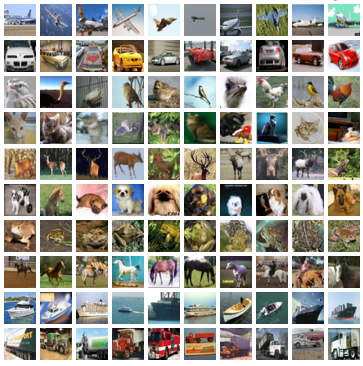

In [ ]:
plt.imshow(X.data[torch.randint(0,len(X), (1,))])
plt.show()

In [ ]:
X.classes

In [ ]:
transforms.Compose([transforms.Resize(64), transforms.ToTensor(), transforms.Normalize(0.5, 0.5)])

In [ ]:
images= torch.from_numpy(X.data).permute(0, 3, 1, 2).float() # B, C, H, W
labels = torch.tensor(X.targets)

Normalization for VAE in range [-1, 1]

In [ ]:
images.max(), images.min()

The input range the VAE was trained on. sd-vae-ft-ema learned to encode images whose pixel values lie in [-1, 1], so the encoder expects that range.

In [ ]:
images.data /=images.data.max()/2 
images-=1 
images.max(), images.min()

In [ ]:
images= F.interpolate(images, size= 64, mode = 'bilinear')

In [ ]:
images.shape , images.max(), images.min()

**Pretrained VAE** (Variational auto encoder)

In [ ]:
from diffusers import AutoencoderKL
VAE = AutoencoderKL.from_pretrained('stabilityai/sd-vae-ft-ema').to(device).eval()  

The latent contains a compressed representation of the image's visual information  
performing diffusion on a smaller latent can be much cheaper than operating directly on every pixel.

In [ ]:
with torch.no_grad():
    batch_size = 256
    latent = []
    for i in range(0,len(images) ,batch_size):
        xt = images[i: i+ batch_size].to(device)
        
        result = VAE.encode(xt)
        result = result.latent_dist.mean
        
        # Vae's raw latents have std of 5.5 --> to normalize * 1/5.5
        latent.append(result*0.18215)  
    latent = torch.cat(latent,dim =0)

In [ ]:
latent.shape, latent.mean(), latent.std().item()

Latent std --> 0.84

In [ ]:
if torch.allclose(latent[0],latent[200]):
    print("failed")
else :
    print("Passed")

In [ ]:
torch.save({"latents": latent.cpu(), "labels": torch.tensor(labels)}, "cifar_latents.pt")

In [ ]:
def show(t):
    g = vu.make_grid(((t.clamp(-1, 1) + 1) / 2).cpu(), nrow=8)
    plt.imshow(g.permute(1, 2, 0)); plt.axis("off"); plt.show()

show(images[:16]); show(result.sample.detach())